# K-Means do zero

O K-Means é um modelo de aprendizado **não supervisionado** que agrupa os dados (determinados por **X**) em um número **k** de grupos, sem precisar de rótulos. Para isso, ele determina pontos que chamamos de **centros** (ou *centroides*), e a cada um deles pertencem os pontos mais próximos. Por organizar vários grupos simultaneamente e pela sua implementação simples, é um dos algoritmos de agrupamento (*clustering*) mais famosos.

Neste notebook, o K-Means é implementado em *Python* com a biblioteca *NumPy* (em `src/kmeans.py`) e, depois, comparado com `sklearn.cluster.KMeans`. Diferente dos notebooks anteriores, aqui não há uma variável Y a prever e a função que o algoritmo minimiza não é convexa, o que terá consequências na comparação.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    silhouette_score
)

from src.kmeans import KMeansDIY

SEED = 42
np.random.seed(SEED)


def plotar_clusters(modelo, x_train, x_test):
    # Gráfico gerado a partir das predições do modelo inserido; dados de treino serão circulares,
    # dados de teste serão quadrados, e os centroides serão X's vermelhos.
    plt.scatter(
        x_train[:, 0], x_train[:, 1],
        c=modelo.predict(x_train),
        s=45,
        alpha=0.8,
        label="Dados de treino"
    )
    plt.scatter(
        x_test[:, 0], x_test[:, 1],
        c=modelo.predict(x_test),
        marker="s",
        s=65,
        alpha=0.9,
        edgecolors="black",
        linewidths=0.8,
        label="Dados de teste"
    )
    plt.scatter(
        modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1],
        marker="X",
        s=100,
        c="red",
        edgecolors="black",
        linewidths=1.5,
        label="Centroides",
        zorder=3
    )
    plt.legend()
    plt.show()


def avaliar(x, y_true, y_pred):
    # Métricas diferentes da acurácia (explicadas adiante); ordem: ARI, NMI, AMI, Silhouette.
    return (
        adjusted_rand_score(y_true, y_pred),
        normalized_mutual_info_score(y_true, y_pred),
        adjusted_mutual_info_score(y_true, y_pred),
        silhouette_score(x, y_pred)
    )

## Como desenvolver

Vamos imaginar como poderíamos chegar ao método do K-Means. Para isso, existe apenas um conceito simples, que aprendemos ainda no ensino fundamental: calcular a distância entre dois pontos de um plano. Imaginemos vários pontos espalhados por um plano cartesiano, como no exemplo abaixo:

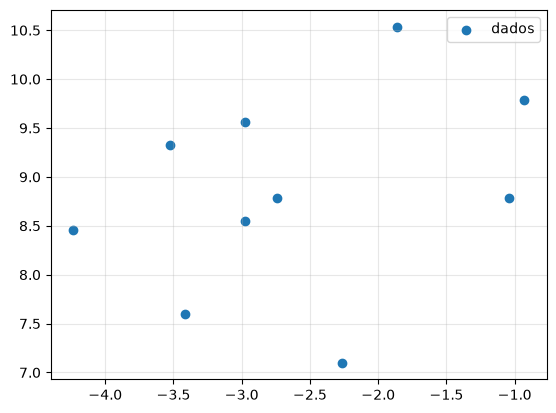

In [2]:
X_ex, y_ex = make_blobs(n_samples=10,
                        centers=1,
                        random_state=SEED)

plt.scatter(X_ex[:, 0], X_ex[:, 1], label="dados")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Se imaginarmos a distância entre dois pontos (P e Q) como a hipotenusa de um triângulo retângulo, cujos catetos são as diferenças entre suas abscissas ($X_p - X_q$) e entre suas ordenadas ($Y_p - Y_q$), o Teorema de Pitágoras ($a^2 = b^2 + c^2$, sendo $a$ a nossa distância) nos leva à seguinte fórmula:

$$D(p,q)^2 = (X_p - X_q)^2 + (Y_p - Y_q)^2$$
$$D(p,q) = \sqrt{(X_p - X_q)^2 + (Y_p - Y_q)^2}$$

E, após muito esforço, chegamos à **distância euclidiana**. É claro que, com os séculos de estudos matemáticos e conhecimento condensado, seríamos capazes de deduzi-la em um único passo. Com mais características, basta somar mais um termo ao quadrado para cada coordenada. Ela será a única coisa que usaremos para encontrar o centro mais próximo de cada ponto.

Vamos introduzir, aleatoriamente, um ponto em nosso plano, que fará o papel de centro:

In [3]:
np.random.seed(SEED)
ponto = np.random.rand(1, X_ex.shape[1])

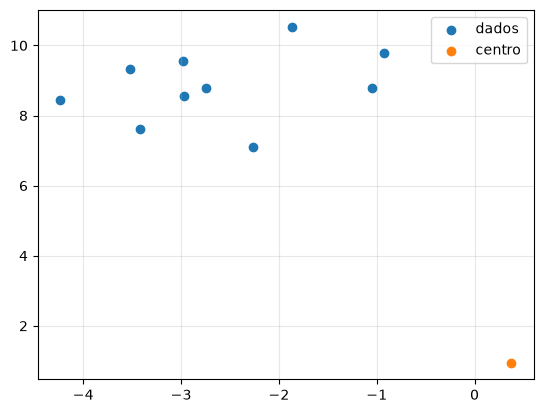

In [4]:
plt.scatter(X_ex[:, 0], X_ex[:, 1], label="dados")
plt.scatter(ponto[0, 0], ponto[0, 1], label="centro")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Tudo bem que o "centro" não esteja no centro: vamos colocá-lo lá calculando a média das posições dos dados (a média de cada coordenada).

Isso determina o funcionamento essencial do K-Means.

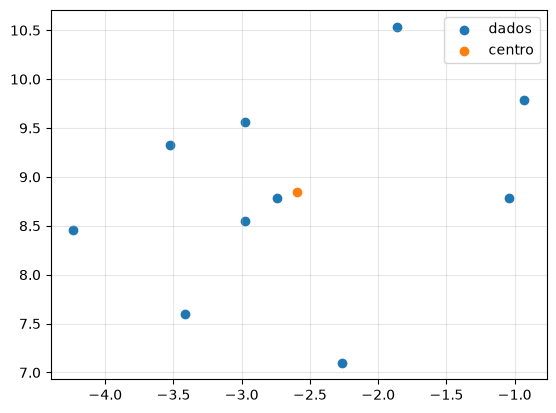

In [5]:
ponto = np.mean(X_ex, axis=0)

plt.scatter(X_ex[:, 0], X_ex[:, 1], label="dados")
plt.scatter(ponto[0], ponto[1], label="centro")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

Redirecionamos o centro para o meio dos dados apenas calculando a média da nuvem. Com vários centros, o procedimento é quase tão simples quanto isso e se repete em dois passos (o algoritmo de Lloyd):

1. **Atribuição:** usando a distância euclidiana, cada ponto é atribuído ao centro mais próximo;
2. **Atualização:** cada centro é movido para a média dos pontos atribuídos a ele (por isso o *means* em K-Means).

Os centros iniciais são sorteados, e os dois passos se repetem até que os centros parem de se mover ou até atingir um número máximo de iterações.

Por que a média? Porque o K-Means minimiza a **inércia**, a soma dos quadrados das distâncias entre cada ponto e o centro do seu grupo:

$$L = \sum_{j=1}^{k}\sum_{x_i \in C_j}\lVert x_i - \mu_j \rVert^2$$

Com os grupos $C_j$ fixos, o passo de atualização encontra exatamente o mínimo dessa soma: derivando em relação a $\mu_j$ e igualando a zero,

$$\frac{\partial L}{\partial \mu_j} = -2\sum_{x_i \in C_j}(x_i - \mu_j) = 0 \quad \Rightarrow \quad \boxed{\mu_j = \frac{1}{|C_j|}\sum_{x_i \in C_j}x_i}$$

Já o passo de atribuição só pode diminuir $L$, já que cada ponto passa a ter o centro mais próximo. Portanto, a inércia nunca aumenta a cada iteração e o algoritmo converge. Há, porém, um detalhe importante: diferente das perdas dos notebooks anteriores, $L$ **não é convexa**, e o algoritmo termina no mínimo local mais próximo dos centros iniciais, que não é necessariamente o global.

Em um cenário realista, nossos dados dificilmente farão grupos perfeitos, e cabe ao analista escolher um **k** prudente para aqueles dados.

## Dados

Geraremos quatro grupos com 300 pontos no total, cada um com um nível de dispersão distinto escolhido arbitrariamente. Os dados são separados em treino (80%), para que o modelo defina seus centros, e teste (20%), para avaliá-lo em dados novos.

**Observação:** como o conjunto criado abaixo tem três características, o gráfico mostra apenas as duas primeiras, para conseguirmos visualizar os pontos em um plano. O modelo continua utilizando as três para calcular os grupos; estamos apenas projetando os resultados em duas dimensões.

Um detalhe: o `sklearn.cluster.KMeans` tem dois algoritmos para calcular as distâncias, `"lloyd"` e `"elkan"`. Por padrão, é usado o `"lloyd"`, o algoritmo clássico, que calcula todas as distâncias (inclusive algumas comparações redundantes) e é o que mais se aproxima do que implementei. O `"elkan"` usa a desigualdade triangular para evitar comparações desnecessárias, ao custo de mais memória, e funciona melhor em dados com centros bem definidos. Neste notebook, usaremos o padrão.

In [6]:
# Dataset sintético
x, y = make_blobs(
    n_samples=300,
    n_features=3,
    centers=4,
    cluster_std=[2.0, 1.5, 3.0, 2.0],
    random_state=SEED
)

# Separação treino/teste
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=SEED)

# Modelos
model_kmeans = KMeansDIY(n_clusters=4)
model_sklearn = KMeans(n_clusters=4, random_state=SEED)   

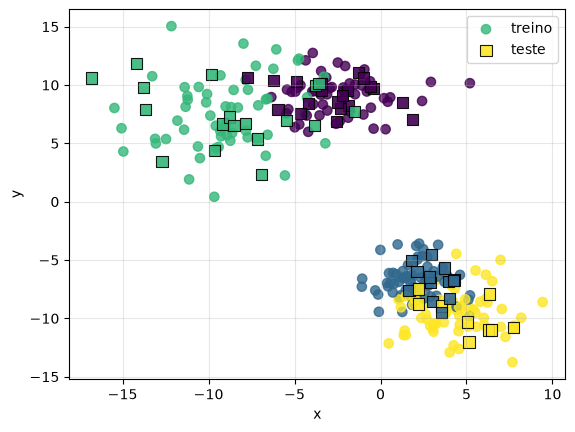

In [7]:
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=45, alpha=0.8, label="treino")
plt.scatter(x_test[:, 0], x_test[:, 1], c=y_test, marker="s", s=65, alpha=0.9, linewidths=0.8, edgecolors="black", label="teste")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Métricas de avaliação

Geralmente, a primeira opção ao avaliar um modelo é a acurácia, mas ela não serve aqui, porque os números dos grupos são arbitrários. Se tivéssemos `y_pred = [0, 0, 1, 1]` e `y_true = [1, 1, 0, 0]`, os dois agrupamentos seriam idênticos, mas a acurácia diria que o modelo não acertou nenhuma amostra.

Uma maneira simples de resolver isso é usar `sklearn.metrics.adjusted_rand_score`. O ARI é simétrico em relação aos nomes dos grupos (`[0, 0, 1, 1]` equivale a `[1, 1, 0, 0]`), retorna um valor entre -0.5 e 1.0 (sendo 1.0 o resultado ideal e agrupamentos aleatórios próximos de 0) e já corrige o acaso.

O `sklearn.metrics.normalized_mutual_info_score` (NMI) diz o quanto os grupos encontrados concordam com as classes reais, em um valor entre 0 e 1 (melhor caso), mas não é ajustado ao acaso. Já o `sklearn.metrics.adjusted_mutual_info_score` (AMI) calcula essencialmente a mesma coisa, só que com o ajuste ao acaso e, por isso, pode retornar valores negativos.

Por último, o `sklearn.metrics.silhouette_score`, ao receber **x** e **y_pred**, avalia a qualidade da separação dos grupos sem precisar dos rótulos verdadeiros (diferente das outras três, ele não compara com `y`). Retorna um valor entre -1 e 1, e valores próximos de zero indicam grupos sobrepostos.

## Treinamento com os hiperparâmetros padrão

Podemos observar que duas nuvens de dados estão bem próximas, o que provavelmente causará um pouco de dor de cabeça para o modelo.

Agora, vamos testar o modelo criado por mim. É esperado que ele chegue a centros parecidos com os do `KMeans` do *scikit-learn* neste *dataset*, mas não necessariamente idênticos: como os centros iniciais são sorteados, o resultado depende da inicialização.

Vale ressaltar que meu modelo usa, por padrão, no máximo 50 iterações, e para antes disso caso os centros parem de se mover. Mesmo assim, precisamos conferir se isso é suficiente.

In [8]:
model_kmeans.fit(x_train)

ari, nmi, ami, silhouette = avaliar(x_test, y_test, model_kmeans.predict(x_test))
print(f"Meu modelo: ARI = {ari:.4f} | NMI = {nmi:.4f} | AMI = {ami:.4f} | Silhouette = {silhouette:.4f}")

# Referência: os próprios rótulos verdadeiros
ari, nmi, ami, silhouette = avaliar(x_test, y_test, y_test)
print(f"Rótulos verdadeiros: ARI = {ari:.4f} | NMI = {nmi:.4f} | AMI = {ami:.4f} | Silhouette = {silhouette:.4f}")

Meu modelo: ARI = 0.8006 | NMI = 0.8471 | AMI = 0.8368 | Silhouette = 0.5322
Rótulos verdadeiros: ARI = 1.0000 | NMI = 1.0000 | AMI = 1.0000 | Silhouette = 0.4570


Todas as métricas acima foram calculadas no **conjunto de teste**. ARI e NMI próximos de 1 indicam que o modelo rotulou bem os dados e que há bastante informação compartilhada: saber os rótulos previstos (`y_pred`) diz quase tudo sobre os rótulos verdadeiros (`y_test`). A AMI ficou um pouco abaixo da NMI, o que mostra que o acaso influenciou levemente a NMI, mas a diferença é pequena.

A Silhouette indica grupos moderadamente separados, o que faz sentido, já que algumas nuvens se sobrepõem. Repare que os próprios rótulos verdadeiros têm uma Silhouette ainda menor: ela mede a separação geométrica dos grupos, e não a concordância com `y_test`, então um agrupamento pode superar os rótulos reais nessa métrica.

No gráfico, a cor de cada ponto vem das previsões do modelo, então ela pode diferir do gráfico anterior (os números dos grupos são arbitrários) e nos permite ver onde o modelo discorda dos rótulos verdadeiros.

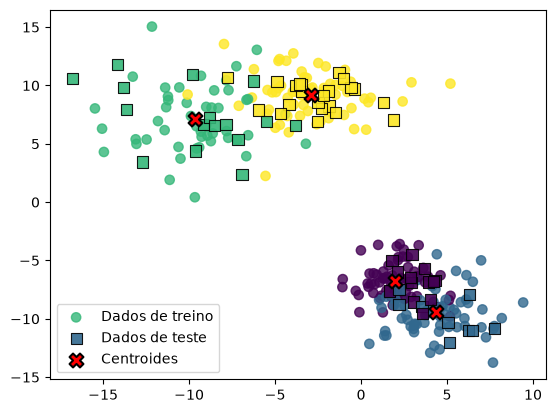

In [9]:
plotar_clusters(model_kmeans, x_train, x_test)

## Comparação com o scikit-learn

Vamos comparar nossos resultados com os do *scikit-learn*. Diferentemente dos notebooks anteriores, nossos dados já estão no formato esperado, isto é, uma matriz com uma coluna por característica. Vale notar que, por padrão, o `KMeans` do *scikit-learn* escolhe os centros iniciais com o método *k-means++*, que tende a espalhá-los, enquanto o nosso parte de centros sorteados.

In [10]:
model_sklearn.fit(x_train)

ari, nmi, ami, silhouette = avaliar(x_test, y_test, model_sklearn.predict(x_test))
print(f"Scikit-Learn: ARI = {ari:.4f} | NMI = {nmi:.4f} | AMI = {ami:.4f} | Silhouette = {silhouette:.4f}")

Scikit-Learn: ARI = 0.8468 | NMI = 0.8939 | AMI = 0.8867 | Silhouette = 0.5410


O resultado do *scikit-learn* foi um pouco melhor que o nosso (ARI de aproximadamente 0,85 contra 0,80), ou seja, seus grupos concordam um pouco mais com os rótulos verdadeiros. A Silhouette é praticamente a mesma, e os dois modelos continuam com dificuldade para separar as nuvens que se sobrepõem. Vejamos o gráfico:

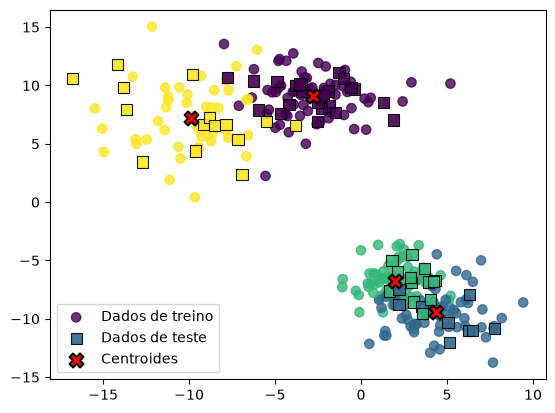

In [11]:
plotar_clusters(model_sklearn, x_train, x_test)

É possível observar um ponto ou outro diferente, mas o resultado final é bastante semelhante. Como é difícil perceber essas mudanças visualmente, vamos comparar os centroides numericamente.

Só que usar `numpy.allclose` diretamente não basta, porque o centroide de índice 0 de um modelo pode corresponder ao de índice 2 do outro: afinal, eles são inicializados aleatoriamente! Então, calculamos a distância entre todos os pares de centroides com `scipy.spatial.distance.cdist` e encontramos o pareamento de menor distância total com `scipy.optimize.linear_sum_assignment`. Dessa forma, temos os centroides equivalentes de cada modelo e é seguro utilizar o `allclose`.

In [12]:
centros_meu = model_kmeans.cluster_centers_
centros_sk = model_sklearn.cluster_centers_

distancias = cdist(centros_meu, centros_sk)

idx_meu, idx_sk = linear_sum_assignment(distancias)

for i, j in zip(idx_meu, idx_sk):
    print(f"Meu centroide {i} <-> sklearn centroide {j}")
    print(f"Meu modelo:   {centros_meu[i]}")
    print(f"Scikit-learn: {centros_sk[j]}")
    print(f"Distância:    {distancias[i, j]:.8f}")
    print("Centroides equivalentes?", np.allclose(centros_meu[i], centros_sk[j], atol=1e-3), "\n")

Meu centroide 0 <-> sklearn centroide 2
Meu modelo:   [ 1.9844661  -6.74192333 -7.06293803]
Scikit-learn: [ 1.9844661  -6.74192333 -7.06293803]
Distância:    0.00000000
Centroides equivalentes? True 

Meu centroide 1 <-> sklearn centroide 1
Meu modelo:   [ 4.34580553 -9.45252309  9.82793413]
Scikit-learn: [ 4.34580553 -9.45252309  9.82793413]
Distância:    0.00000000
Centroides equivalentes? True 

Meu centroide 2 <-> sklearn centroide 3
Meu modelo:   [-9.63304701  7.13830296  0.71458425]
Scikit-learn: [-9.89072367  7.21920484  0.96611998]
Distância:    0.36906991
Centroides equivalentes? False 

Meu centroide 3 <-> sklearn centroide 0
Meu modelo:   [-2.90323553  9.1546333   4.63617718]
Scikit-learn: [-2.82045105  9.06511455  4.3939653 ]
Distância:    0.27117056
Centroides equivalentes? False 



Dos quatro centroides, dois coincidiram (a diferença é menor que $10^{-8}$) e os outros dois ficaram a aproximadamente 0,37 e 0,27 de distância. Isso pode ter duas explicações: o nosso modelo parou antes de convergir (as 50 iterações não bastaram) ou ele convergiu para um ponto diferente do *scikit-learn*.

## Por que os centroides diferem?

Para separar as duas explicações, usamos a **inércia** definida acima (a função de perda do K-Means), calculada para os dois conjuntos de centroides. Também reiniciamos o K-Means do *scikit-learn* partindo dos centroides finais de cada modelo: se eles já são um ponto de convergência, o algoritmo não os move.

In [13]:
def inercia(x, centros):
    # Soma dos quadrados das distâncias entre cada ponto e o centroide mais próximo.
    return np.sum(np.min(cdist(x, centros) ** 2, axis=1))


for nome, centros in [("Meu modelo", centros_meu), ("scikit-learn", centros_sk)]:
    reinicio = KMeans(n_clusters=4, init=centros, n_init=1).fit(x_train)
    deslocamento = np.abs(reinicio.cluster_centers_ - centros).max()
    print(f"{nome:<13} inércia = {inercia(x_train, centros):.4f} | deslocamento ao reiniciar = {deslocamento:.1e}")

Meu modelo    inércia = 3147.7037 | deslocamento ao reiniciar = 5.3e-15
scikit-learn  inércia = 3146.3073 | deslocamento ao reiniciar = 0.0e+00


Reiniciar não move nenhum dos dois conjuntos de centroides (os deslocamentos são desprezíveis), ou seja, ambos já estavam em um ponto de convergência. Logo, as 50 iterações foram suficientes e a diferença não vem do número de iterações, e sim do ponto de partida: como a inércia **não é convexa**, o K-Means termina no mínimo local mais próximo dos centros iniciais, e os dois modelos caíram em mínimos locais diferentes, mas muito próximos (inércia de aproximadamente 3147,70 contra 3146,31). Isso é esperado quando há nuvens sobrepostas, onde pequenas mudanças na fronteira entre os grupos geram soluções estáveis ligeiramente diferentes. A do *scikit-learn* tem a menor inércia, o que combina com o seu ARI um pouco mais alto.

Na prática, por isso, o K-Means costuma ser executado várias vezes com inicializações diferentes (o parâmetro `n_init` no *scikit-learn*), mantendo o resultado de menor inércia, e usa-se o *k-means++* para espalhar os centros iniciais.

## Limitações

- **Inicialização**: os centros iniciais saem de `np.random.rand`, ou seja, em $[0, 1)$, independente de onde os dados estão. Aqui funcionou, mas com dados em outra escala ou posição os centros podem começar longe de tudo, e um centro sem nenhum ponto atribuído gera uma média de conjunto vazio. 
- **Mínimos locais**: como a inércia não é convexa, um único treino não basta. O scikit-learn roda várias inicializações (*n_init*) e mantém a de menor inércia, e o nosso modelo poderia fazer o mesmo.
- **k escolhido de antemão**: usamos 4 porque sabíamos que eram 4 grupos. Em dados reais, é preciso estimá-lo (método do cotovelo ou Silhouette).
- **Escala e formato dos grupos**: a distância euclidiana pressupõe variáveis na mesma escala (convém padronizá-las) e favorece grupos esféricos e de tamanho parecido. As dispersões diferentes que usamos já dificultam um pouco.
- **Métricas externas**: ARI, NMI e AMI só existem porque temos os rótulos, o que não acontece na prática. Num caso real, restariam Silhouette e inércia.

## Conclusão

- Dois centroides coincidiram com o scikit-learn e os outros dois ficaram a 0,37 e 0,27 de distância, com ARI de 0,80 contra 0,85.
- As 50 iterações foram suficientes: reiniciar o K-Means a partir dos centroides finais não os move, em nenhum dos dois modelos.
- A diferença vem de mínimos locais distintos (inércia de 3147,70 contra 3146,31), e não de falta de iterações. É a consequência prática de a inércia não ser convexa, o que não acontecia nas regressões.
- A Silhouette mede a separação geométrica e não a concordância com os rótulos: os rótulos verdadeiros têm 0,457, menos que os dois modelos.